# Tetrahedral ⇄ polyhedral conversion: `tet_to_poly` and `poly_to_tet`

Polyhedral meshes are first-class in meshio++ (`polyhedron` blocks, read and written by VTU, VTKHDF, OpenFOAM, CGNS, MED, EnSight and Tecplot). This notebook shows the two conversions between them and tetrahedral meshes:

| operation | does | result |
|---|---|---|
| `tet_to_poly(mesh)` | the **median dual**, the tet-to-poly conversion CFD meshers perform | one polyhedron per vertex, about 4-6x fewer cells |
| `poly_to_tet(mesh)` | `convert_cells(mode="simplexify")`, keeping a polyhedron that already is a tetrahedron as one `tetra` | a tetrahedral mesh of the same volume |

Each dual cell is bounded by the ring of tetrahedron and triangle centroids around every edge leaving its vertex and, on the boundary, by its share of the boundary triangles, fused while their normals agree within `feature_angle`. See `doc/tet_poly.md`.

In [1]:
import os
import subprocess
import sys
import tempfile
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        # Head-less, static rendering (no display / live server needed).
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')

# Renders the documentation embeds are written here as well as shown.
DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')


def show(img, title=None, figsize=(6, 4.5), save=None):
    """Embed a rendered RGB screenshot; with `save`, also write doc/public/images/<save>.png."""
    if save:
        try:
            os.makedirs(DOC_IMAGES, exist_ok=True)
            plt.imsave(os.path.join(DOC_IMAGES, save + '.png'), img)
        except Exception as exc:  # pragma: no cover - read-only checkout
            print('doc image not written:', exc)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis('off')
    if title:
        plt.title(title)
    plt.tight_layout()
    plt.show()


def to_pyvista(mesh):
    """meshio++ Mesh -> pyvista grid via a temporary .vtu."""
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def cell_faces(mesh):
    """Per volume cell: its faces as point-id lists, over every tetra/polyhedron block."""
    out = []
    for block in mesh.cells:
        if block.type == 'tetra':
            for a, b, c, d in np.asarray(block.data):
                out.append([[b, c, d], [a, d, c], [a, b, d], [a, c, b]])
        elif block.type.startswith('polyhedron'):
            out += [[list(f) for f in cell] for cell in block.data]
    return out


def mpl_cutaway(mesh, ax, values=None, cmap='viridis', shrink=0.85, title=None):
    """Matplotlib fallback: the cells whose centroid has y < 0, each shrunk to its centroid."""
    polys, colours = [], []
    norm = plt.Normalize(*(np.nanmin(values), np.nanmax(values))) if values is not None else None
    for i, faces in enumerate(cell_faces(mesh)):
        ids = sorted({p for f in faces for p in f})
        c = mesh.points[ids].mean(axis=0)
        if c[1] >= 0:
            continue
        for f in faces:
            polys.append(c + shrink * (mesh.points[f] - c))
            colours.append(plt.get_cmap(cmap)(norm(values[i])) if values is not None else '#2ec4b6')
    ax.add_collection3d(Poly3DCollection(polys, facecolors=colours, edgecolors='#1f4e79', linewidths=0.1))
    lim = np.abs(mesh.points).max()
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim))
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=20, azim=60)
    ax.set_axis_off()
    if title:
        ax.set_title(title)


def render_cutaway(mesh, title, scalars=None, cmap='viridis', save=None):
    """Cells with centroid y < 0, shrunk so each one is visible: PyVista, else matplotlib."""
    if pv is not None:
        try:
            grid = to_pyvista(mesh)
            keep = np.flatnonzero(grid.cell_centers().points[:, 1] < 0)
            part = grid.extract_cells(keep).shrink(0.85)
            pl = pv.Plotter(off_screen=True, window_size=(900, 700))
            if scalars:
                pl.add_mesh(part, scalars=scalars, cmap=cmap, show_edges=True, edge_color='#1f4e79',
                            line_width=0.3, scalar_bar_args={'title': scalars})
            else:
                pl.add_mesh(part, color='#2ec4b6', show_edges=True, edge_color='#1f4e79', line_width=0.3)
            pl.camera_position = [(2.4, 4.4, 1.8), (0, 0, 0), (0, 0, 1)]
            img = pl.screenshot(return_img=True)
            pl.close()
            show(img, title, save=save)
            return
        except Exception as exc:  # pragma: no cover - GL failure mid-run
            print('PyVista render skipped:', exc)
    values = None
    if scalars:
        values = np.concatenate([np.asarray(a, float).ravel() for a in mesh.cell_data[scalars]])
    fig = plt.figure(figsize=(6, 4.5))
    mpl_cutaway(mesh, fig.add_subplot(projection='3d'), values, cmap, title=title)
    plt.tight_layout()
    plt.show()


def volume(mesh):
    return mp.compute_stats(mesh)['signed_volume']

## A tetrahedral mesh

A ball of radius 1 meshed with tetrahedra by the `ball` primitive. Rendered as a cut-away, with each cell shrunk towards its centroid so the individual cells are visible.

points    : 2197
tetrahedra: 10368
volume    : 4.153597 (a sphere of radius 1 is 4.188790)


2026-10-31 18:19:27.509 (   1.826s) [    7F3A45C06080]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


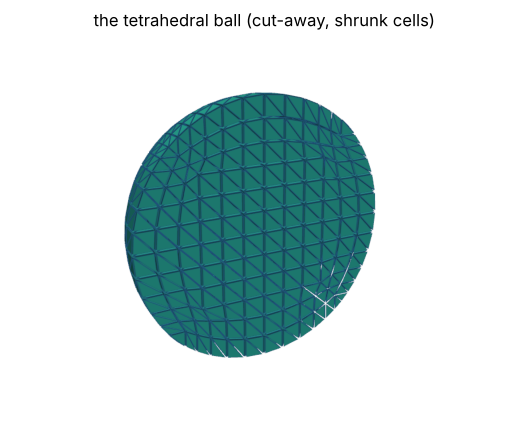

In [2]:
tets = mp.ball(n=6, cell_type='tetra')
print('points    :', len(tets.points))
print('tetrahedra:', sum(len(c.data) for c in tets.cells))
print('volume    : %.6f (a sphere of radius 1 is %.6f)' % (volume(tets), 4 / 3 * np.pi))
render_cutaway(tets, 'the tetrahedral ball (cut-away, shrunk cells)')

## `tet_to_poly`: one polyhedron per vertex

Every vertex becomes one cell. The cell count drops to the vertex count, and each cell has many more faces, so many more neighbours, than a tetrahedron's four. That is why polyhedral meshes give better gradients per cell. The new points are the edge midpoints on the boundary, the triangle centroids and the tetrahedron centroids, appended after the original points, which keep their indices.

meshio warning [region_remap.cpp:525] tet_to_poly: side region 'surface' lost 1728 of its 1728 facet(s) — they have no counterpart in the output


blocks            : [('polyhedron', 2197)]
cells             : 10368 tetrahedra -> 2197 polyhedra (4.7x fewer)
faces per cell    : min 8, mean 14.3, max 16
report            : {'num_new_points': 34560, 'num_boundary_faces': 4608, 'num_split_vertices': 0}
volume            : 4.153597104585  (tetrahedra 4.153597104585)


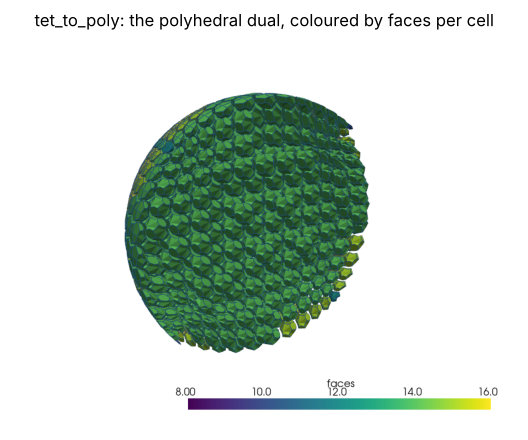

In [3]:
poly, report = mp.tet_to_poly(tets, return_report=True)
faces_per_cell = np.array([len(cell) for cell in poly.cells[0].data])
poly.cell_data['faces'] = [faces_per_cell.astype(float)]

print('blocks            :', [(c.type, len(c.data)) for c in poly.cells])
print('cells             : %d tetrahedra -> %d polyhedra (%.1fx fewer)'
      % (sum(len(c.data) for c in tets.cells), len(poly.cells[0].data),
         sum(len(c.data) for c in tets.cells) / len(poly.cells[0].data)))
print('faces per cell    : min %d, mean %.1f, max %d' % (faces_per_cell.min(), faces_per_cell.mean(), faces_per_cell.max()))
print('report            :', {k: v for k, v in report.items() if k != 'vertex_map'})
print('volume            : %.12f  (tetrahedra %.12f)' % (volume(poly), volume(tets)))
render_cutaway(poly, 'tet_to_poly: the polyhedral dual, coloured by faces per cell',
               scalars='faces', save='tet_to_poly')

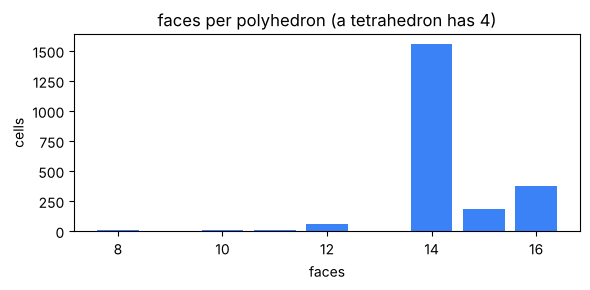

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
counts = Counter(faces_per_cell.tolist())
ax.bar(list(counts), list(counts.values()), color='#3b82f6')
ax.set(title='faces per polyhedron (a tetrahedron has 4)', xlabel='faces', ylabel='cells')
plt.tight_layout()
plt.show()

## The feature angle

On the boundary, each vertex's share of the boundary triangles is fused into one polygon per run of triangles whose normals agree within `feature_angle` degrees. The default of 1 degree keeps every boundary face planar, so the volume is conserved to rounding. A larger angle fuses more of a curved boundary into fewer, non-planar faces, which changes the volume slightly.

meshio warning [region_remap.cpp:525] tet_to_poly: side region 'surface' lost 1728 of its 1728 facet(s) — they have no counterpart in the output
meshio warning [region_remap.cpp:525] tet_to_poly: side region 'surface' lost 1728 of its 1728 facet(s) — they have no counterpart in the output
meshio warning [region_remap.cpp:525] tet_to_poly: side region 'surface' lost 1728 of its 1728 facet(s) — they have no counterpart in the output
meshio warning [region_remap.cpp:525] tet_to_poly: side region 'surface' lost 1728 of its 1728 facet(s) — they have no counterpart in the output
meshio warning [stats.cpp:189] stats: 24 polyhedron cell(s) in block 'polyhedron' are not closed orientable surfaces; their volume is not defined and is excluded
meshio warning [region_remap.cpp:525] tet_to_poly: side region 'surface' lost 1728 of its 1728 facet(s) — they have no counterpart in the output


feature_angle  boundary faces  volume - tet volume
            1            4608  -4.352e-14
            2            4032  -7.590e-05
            3            3648  -8.270e-05
            5            3032  -1.127e-02
           10             866  -2.670e-02


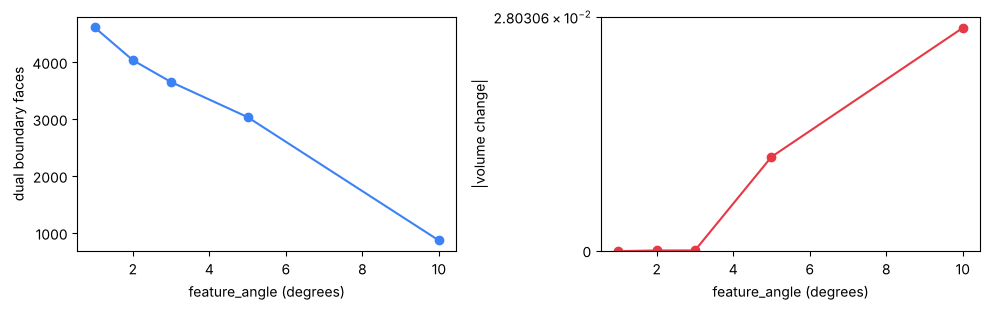

In [5]:
rows = []
for angle in (1, 2, 3, 5, 10):
    out, rep = mp.tet_to_poly(tets, feature_angle=angle, return_report=True)
    rows.append((angle, rep['num_boundary_faces'], volume(out) - volume(tets)))
print('feature_angle  boundary faces  volume - tet volume')
for angle, nb, dv in rows:
    print('%13g  %14d  %+.3e' % (angle, nb, dv))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot([r[0] for r in rows], [r[1] for r in rows], 'o-', color='#3b82f6')
axes[0].set(xlabel='feature_angle (degrees)', ylabel='dual boundary faces')
axes[1].plot([r[0] for r in rows], [abs(r[2]) for r in rows], 'o-', color='#e63946')
axes[1].set(xlabel='feature_angle (degrees)', ylabel='|volume change|', yscale='symlog', ylim=(0, None))
plt.tight_layout()
plt.show()

## Nodal fields become cell fields

A vertex's dual cell is the natural home of its nodal value: `point_data_to_cell_data=True` copies each vertex's `point_data` onto its cell. Existing `cell_data` is volume-weighted over the tetrahedra a cell is built from (integer arrays take the largest tetrahedron's value), and `point_data` is extended to the new points by averaging.

meshio warning [region_remap.cpp:525] tet_to_poly: side region 'surface' lost 1728 of its 1728 facet(s) — they have no counterpart in the output


cell_data : ['dual:vertex', 'r']
point_data: ['r'] - extended to 36757 points


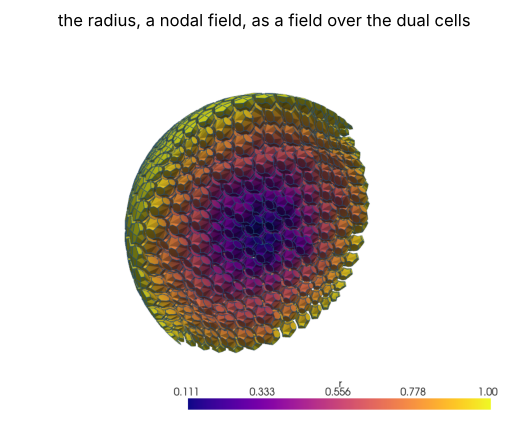

In [6]:
tets.point_data['r'] = np.linalg.norm(tets.points, axis=1)
poly_r = mp.tet_to_poly(tets, point_data_to_cell_data=True, record_vertex_ids=True)
vid = poly_r.cell_data['dual:vertex'][0]
assert np.array_equal(poly_r.cell_data['r'][0], tets.point_data['r'][vid])
print('cell_data :', sorted(poly_r.cell_data))
print('point_data:', sorted(poly_r.point_data), '- extended to', len(poly_r.points), 'points')
render_cutaway(poly_r, 'the radius, a nodal field, as a field over the dual cells', scalars='r', cmap='plasma')

## `poly_to_tet`: back to tetrahedra

Each polyhedron of the dual is fanned into tetrahedra from its corner average through each face's corner average. This is the same decomposition the polyhedron kernel measures volumes with, so the volume is conserved exactly. The result is a valid tetrahedral mesh, but not the original one: the dual has forgotten the original tetrahedra.

blocks : [('tetra', 278784)]
report : {'num_exact_tets': 0, 'num_fanned_cells': 2197}


volume : 4.153597104584  (dual 4.153597104585)


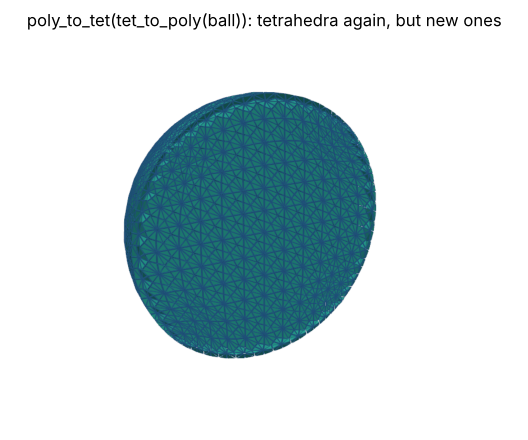

In [7]:
back, rep = mp.poly_to_tet(poly, return_report=True)
print('blocks :', [(c.type, len(c.data)) for c in back.cells])
print('report :', {k: v for k, v in rep.items() if k in ('num_exact_tets', 'num_fanned_cells')})
print('volume : %.12f  (dual %.12f)' % (volume(back), volume(poly)))
render_cutaway(back, 'poly_to_tet(tet_to_poly(ball)): tetrahedra again, but new ones')

### The exact inverse

A polyhedron that already is a tetrahedron (four triangles over four nodes), as some readers produce, comes back as exactly that tetrahedron, positively oriented, with no new points, whatever the winding of its faces.

In [8]:
as_polyhedra = mp.Mesh(
    tets.points,
    [('polyhedron4', [[[b, c, d], [a, d, c], [a, b, d], [a, c, b]] for a, b, c, d in tets.cells[0].data])],
)
again, rep = mp.poly_to_tet(as_polyhedra, return_report=True)
same = sorted(map(tuple, np.sort(again.cells[0].data, axis=1))) == sorted(map(tuple, np.sort(tets.cells[0].data, axis=1)))
p = again.points[again.cells[0].data]
signed = np.einsum('ij,ij->i', np.cross(p[:, 1] - p[:, 0], p[:, 2] - p[:, 0]), p[:, 3] - p[:, 0])
print('exact tets      :', rep['num_exact_tets'], 'of', len(tets.cells[0].data))
print('new points      :', len(again.points) - len(tets.points))
print('same tetrahedra :', same)
print('all positive    :', bool((signed > 0).all()))

exact tets      : 10368 of 10368
new points      : 0
same tetrahedra : True
all positive    : True


## Elsewhere

The same operations are on the CLI (`meshioplusplus tet-to-poly IN OUT --feature-angle 30 --json`, `meshioplusplus poly-to-tet IN OUT`), as the `TetToPoly`/`PolyToTet` pipeline steps, as MCP tools, and in the C, Fortran, Julia, R and WebAssembly bindings.